# 1. Import Library

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.model_selection import train_test_split

# 2. Load Dataset

## 2.1 Data Train

In [68]:
df = pd.read_csv('data/jena_climate_2009_2016.csv')
df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


# 3. EDA Awal

## 3.1 ukuran dataset

In [69]:
df.shape

(420551, 15)

## 3.2 type dan informasi data

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  str    
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), str(1)
memory usage: 55.7 MB


## 3.3 Statistik Deskriptif

In [71]:
df.describe()

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000
mean,989.212776,9.450147,283.492743,4.955854,76.008259,13.576251,9.533756,4.042412,6.022408,9.640223,1216.062748,1.702224,3.056555,174.743738
std,8.358481,8.423365,8.504471,6.730674,16.476175,7.739020,4.184164,4.896851,2.656139,4.235395,39.975208,65.446714,69.016932,86.681693
min,913.600000,-23.010000,250.600000,-25.010000,12.950000,0.950000,0.790000,0.000000,0.500000,0.800000,1059.450000,-9999.000000,-9999.000000,0.000000
25%,984.200000,3.360000,277.430000,0.240000,65.210000,7.780000,6.210000,0.870000,3.920000,6.290000,1187.490000,0.990000,1.760000,124.900000
50%,989.580000,9.420000,283.470000,5.220000,79.300000,11.820000,8.860000,2.190000,5.590000,8.960000,1213.790000,1.760000,2.960000,198.100000
75%,994.720000,15.470000,289.530000,10.070000,89.400000,17.600000,12.350000,5.300000,7.800000,12.490000,1242.770000,2.860000,4.740000,234.100000
max,1015.350000,37.280000,311.340000,23.110000,100.000000,63.770000,28.320000,46.010000,18.130000,28.820000,1393.540000,28.490000,23.500000,360.000000


## 3.4 cek distribusi data

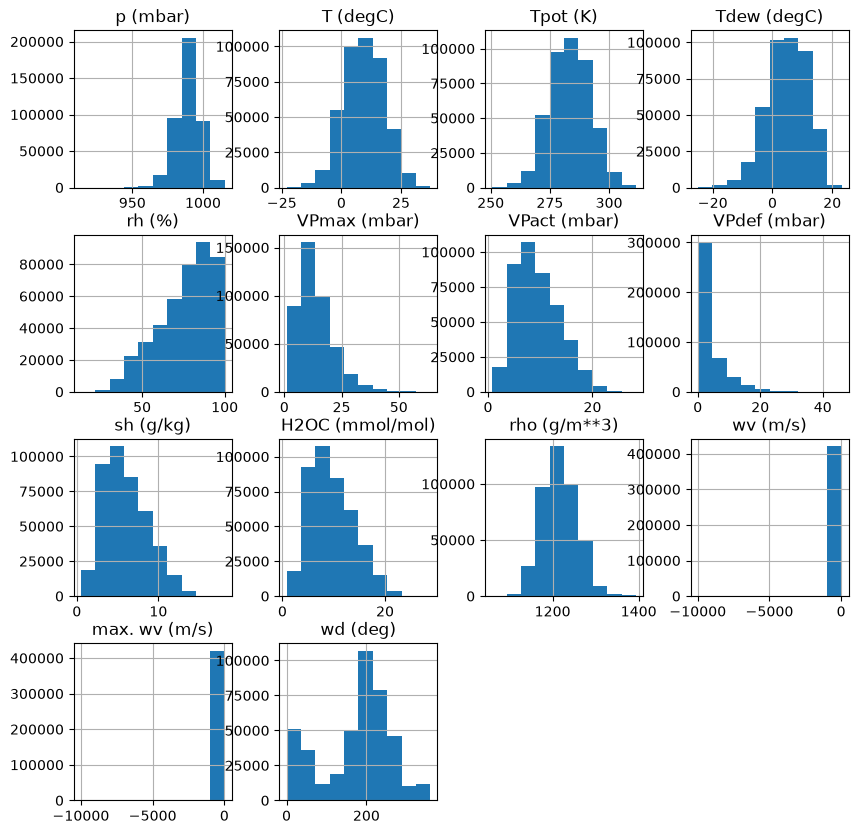

In [72]:
df.hist(figsize=(10,10))
plt.savefig('images/distribusi data.png', dpi=300, bbox_inches='tight')


## 3.5 cek outlier

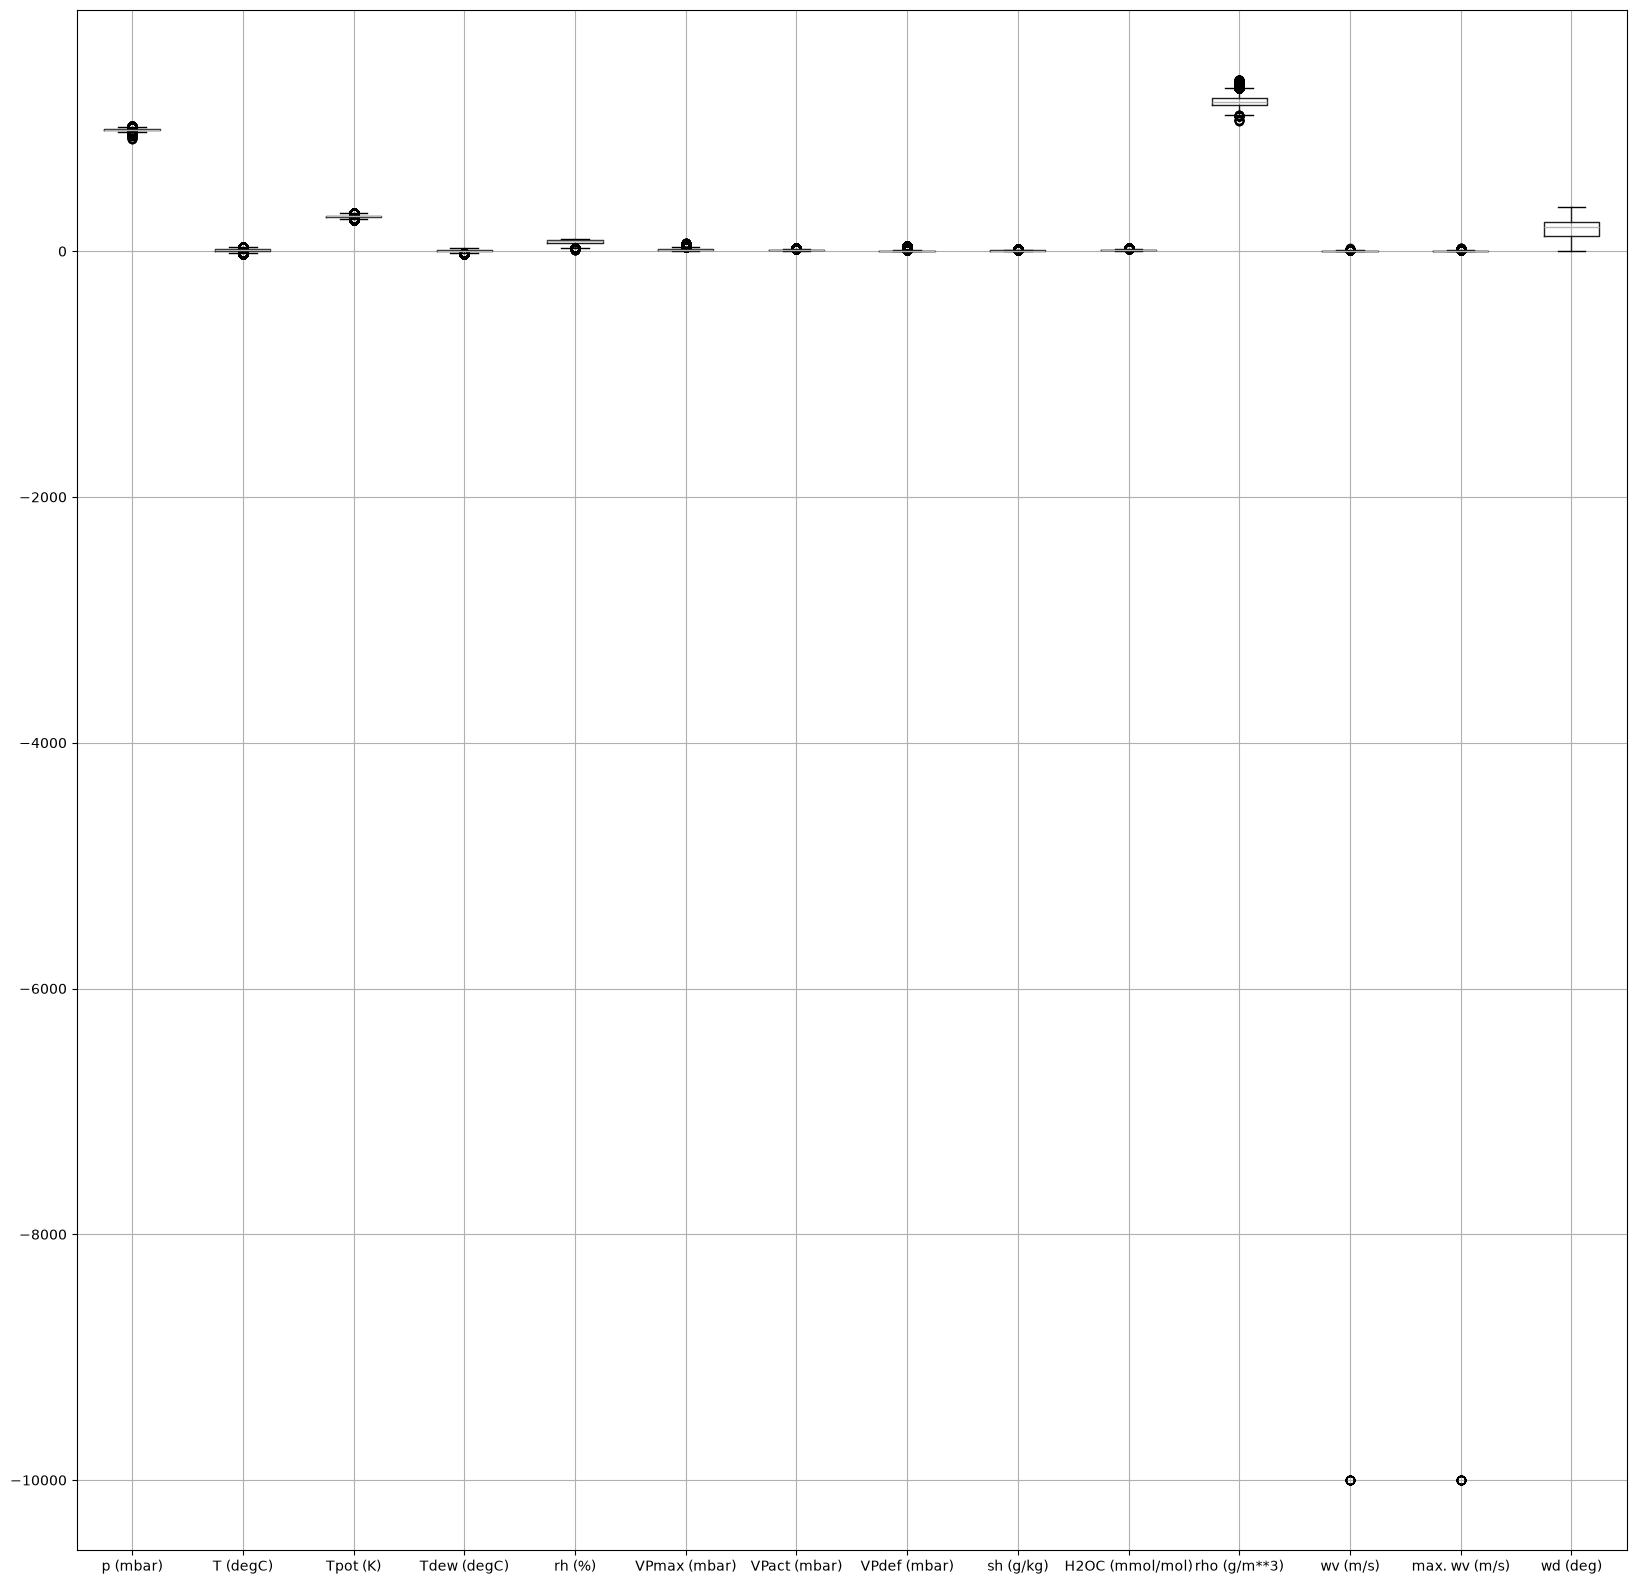

In [73]:
df.boxplot(figsize=(20,20))
plt.savefig('images/boxplot dengan outlier.png', dpi=300, bbox_inches='tight')


# 4. Data Cleaning

## 4.1 Cek dan tangani Missing value

In [74]:
df.isnull().sum()

Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
dtype: int64

## 4.2 cek dan tangani nilai duplikat

In [75]:
df['Date Time'].duplicated().sum()

np.int64(327)

In [76]:
df = df.drop_duplicates(subset='Date Time',keep='last')

In [77]:
df['Date Time'].duplicated().sum()

np.int64(0)

## 4.3 Ubah ke datetime, urutkan, jadikan index

In [78]:
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df = df.sort_values('Date Time').set_index('Date Time')
print(df.index.min(), '->', df.index.max())


2009-01-01 00:10:00 -> 2017-01-01 00:00:00


## 4.4 Tangani nilai -9999 

In [79]:
for c in ['wv (m/s)', 'max. wv (m/s)']:
    print(c, '-> jumlah -9999:', (df[c] == -9999.0).sum())
    df.loc[df[c] == -9999.0, c] = np.nan
    df[c] = df[c].interpolate(method='time')

print(df[['wv (m/s)', 'max. wv (m/s)']].min())   # harus >= 0

wv (m/s) -> jumlah -9999: 18
max. wv (m/s) -> jumlah -9999: 20
wv (m/s)         0.0
max. wv (m/s)    0.0
dtype: float64


# 5. EDA lanjutan

## 5.1 Statistik Deskriptif

In [80]:
df.describe()


,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000,420224.000000
mean,989.214157,9.442421,283.484880,4.953472,76.028738,13.568642,9.532333,4.036225,6.021503,9.638778,1216.097805,2.129972,3.530998,174.748064
std,8.360888,8.421135,8.502206,6.731171,16.460467,7.734770,4.183996,4.891287,2.656043,4.235244,39.967936,1.544301,2.338056,86.685323
min,913.600000,-23.010000,250.600000,-25.010000,12.950000,0.950000,0.790000,0.000000,0.500000,0.800000,1059.450000,0.000000,0.000000,0.000000
25%,984.200000,3.360000,277.430000,0.230000,65.240000,7.770000,6.210000,0.870000,3.920000,6.280000,1187.540000,0.990000,1.760000,124.900000
50%,989.580000,9.400000,283.460000,5.210000,79.300000,11.810000,8.860000,2.180000,5.590000,8.960000,1213.830000,1.760000,2.960000,198.100000
75%,994.730000,15.460000,289.520000,10.070000,89.400000,17.590000,12.350000,5.290000,7.800000,12.480000,1242.790000,2.860000,4.730000,234.100000
max,1015.350000,37.280000,311.340000,23.110000,100.000000,63.770000,28.320000,46.010000,18.130000,28.820000,1393.540000,28.490000,23.500000,360.000000


## 5.2 outlier

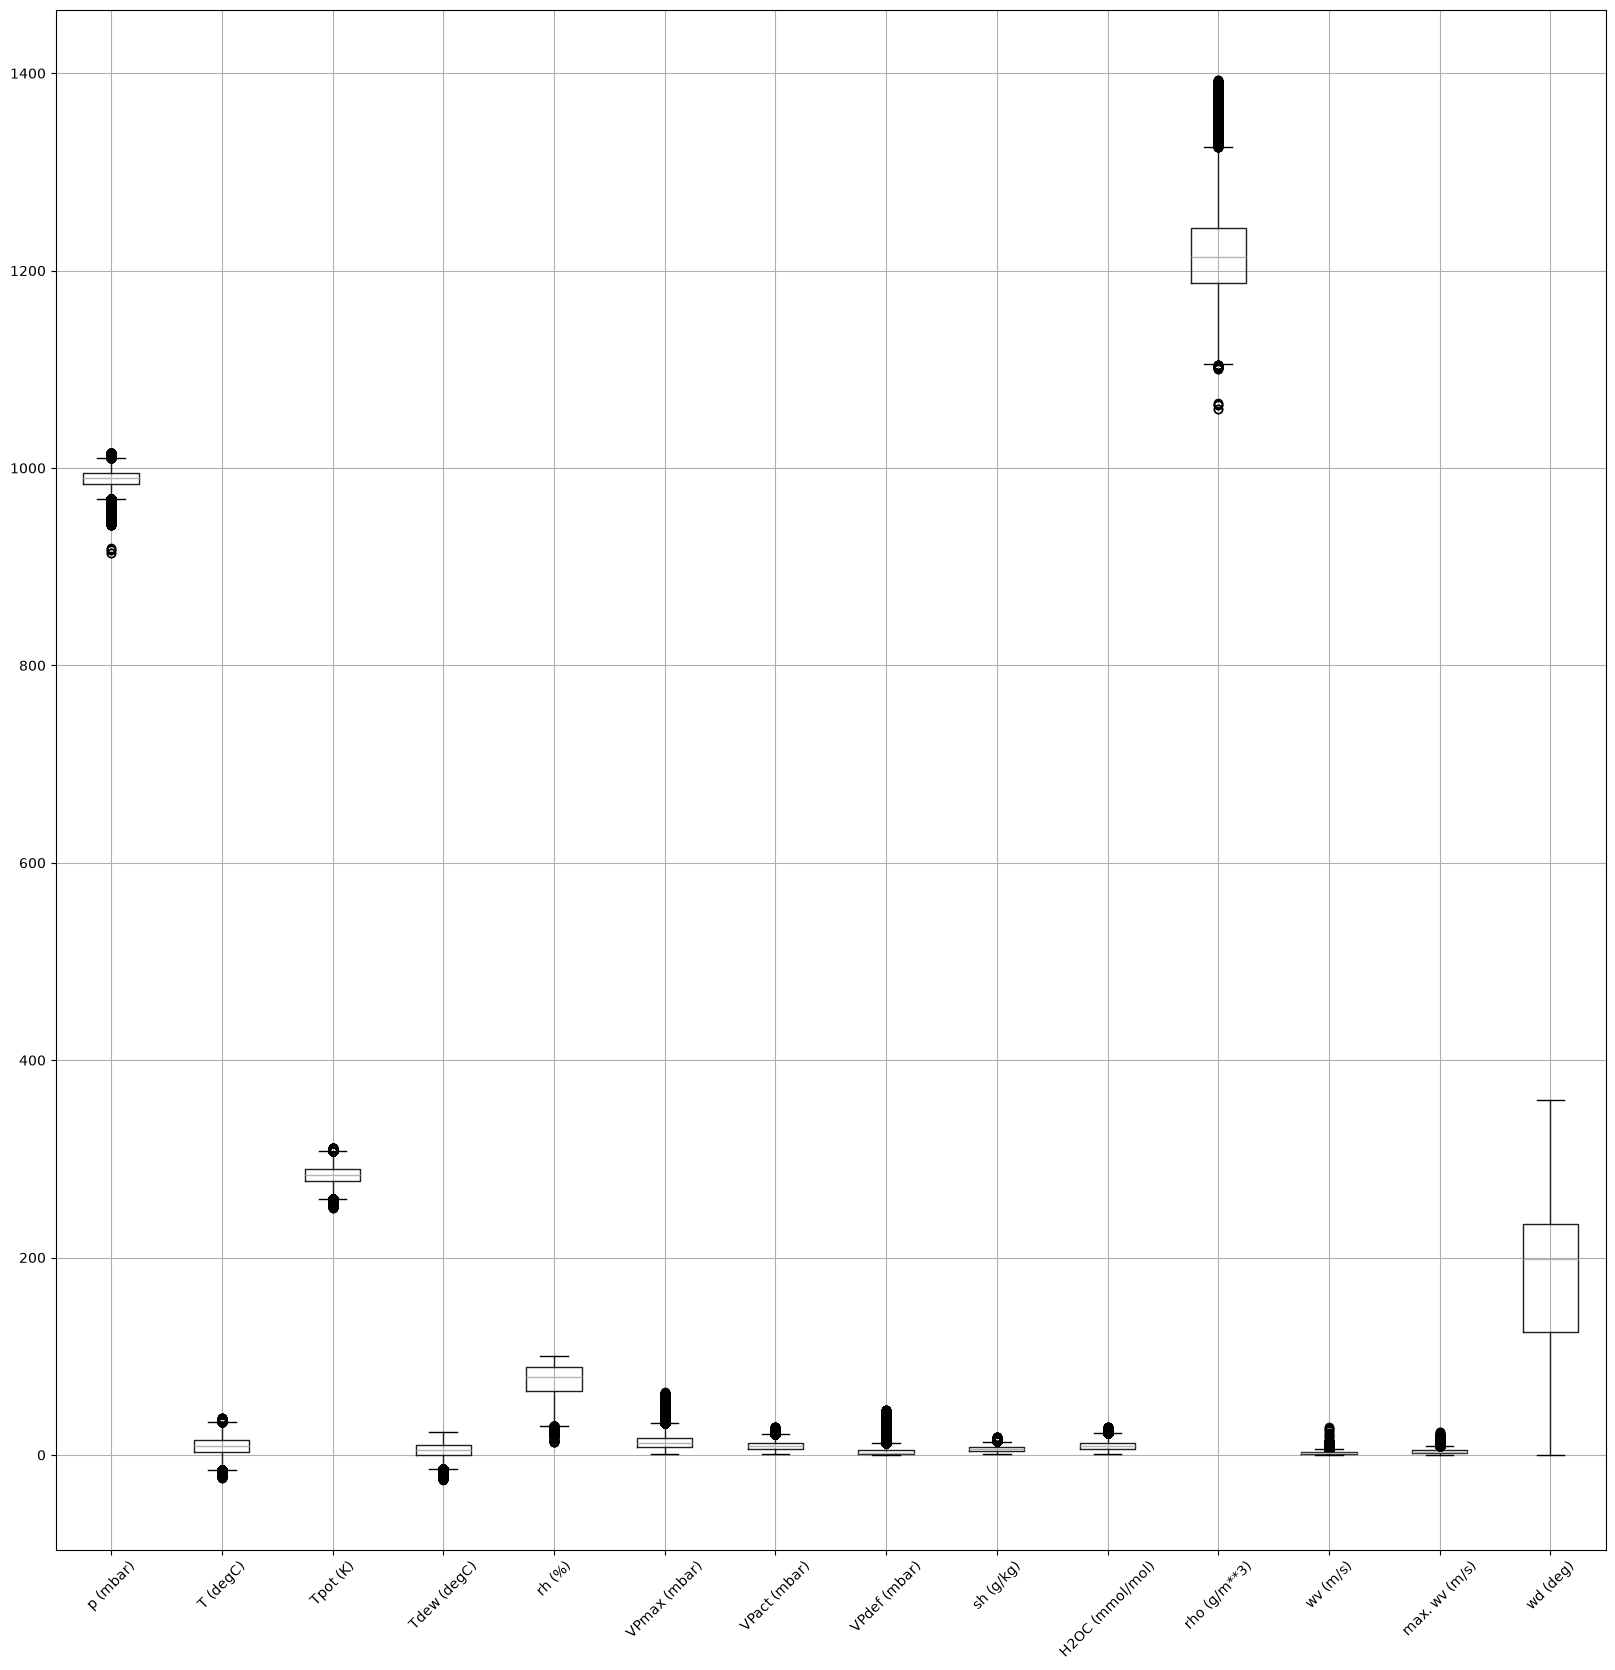

In [81]:
df.boxplot(figsize=(20,20))
plt.xticks(rotation=45)
plt.savefig('images/boxplot setelah cleaning.png', dpi=300, bbox_inches='tight')
plt.show()

## 5.3 korelasi

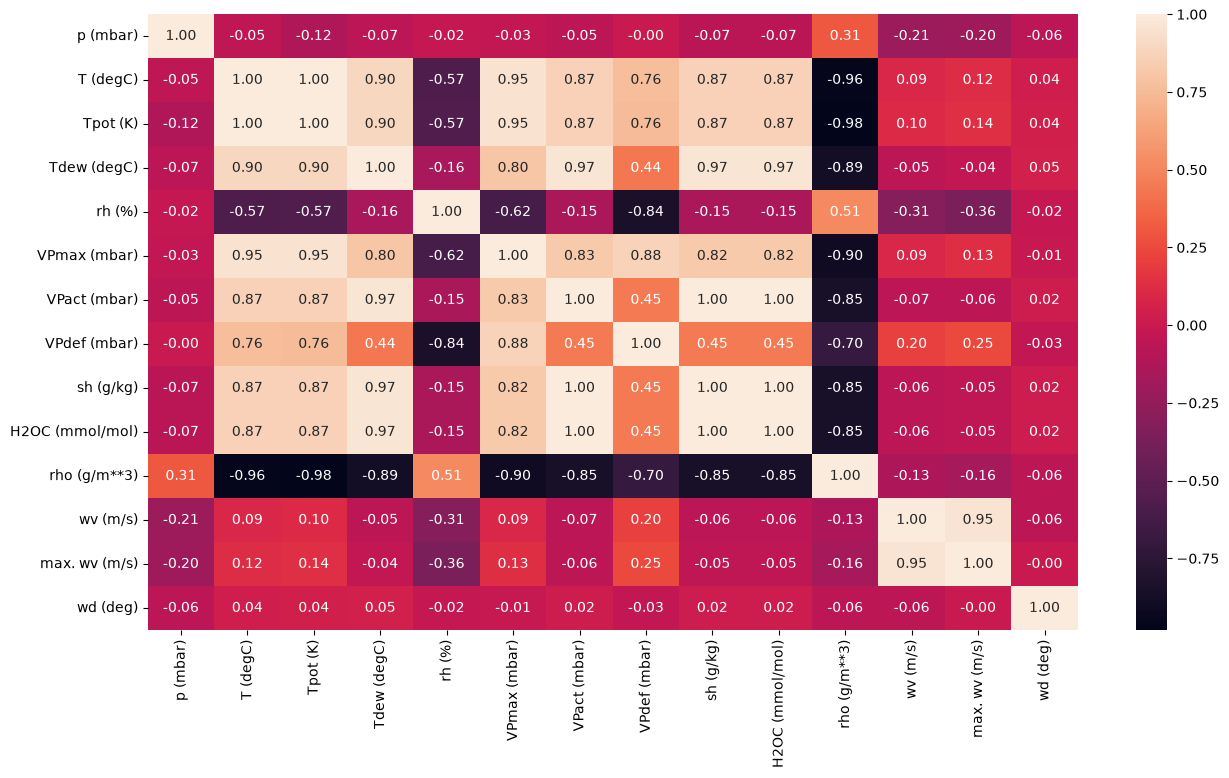

In [82]:
import seaborn as sns
plt.figure(figsize=(15, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f')
plt.savefig('images/heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 5.4 Overall daily temperature

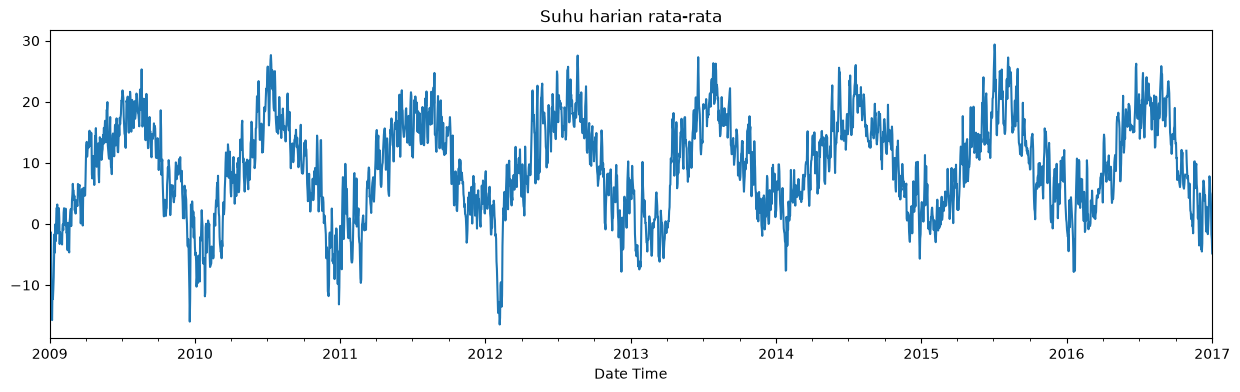

In [83]:
daily_T = df['T (degC)'].resample('1D').mean()
daily_T.plot(figsize=(15, 4), title='Suhu harian rata-rata')
plt.savefig('images/Overall daily temperature.png', dpi=300, bbox_inches='tight')
plt.show()

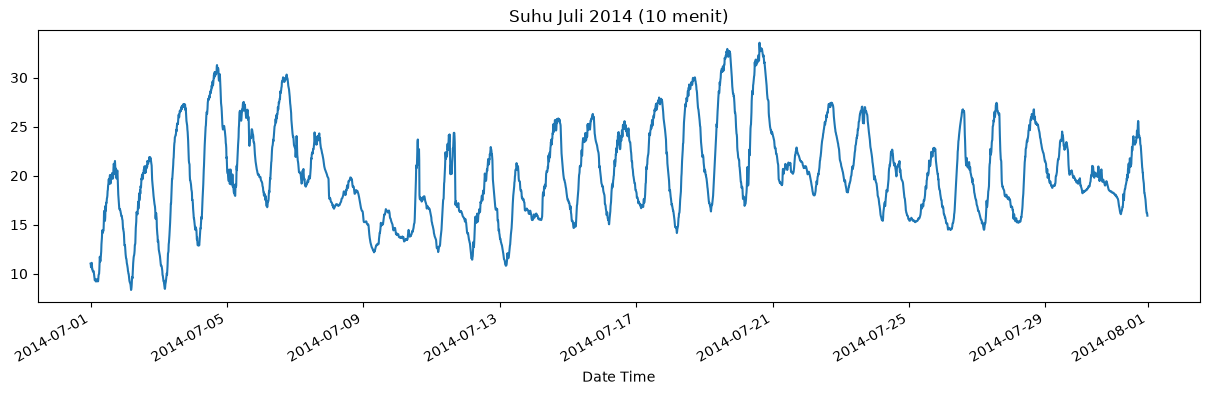

In [84]:
df['T (degC)'].loc['2014-07'].plot(figsize=(15,4),title ='Suhu Juli 2014 (10 menit)')
plt.savefig('images/Overall daily temperature_Juli_2014.png', dpi=300, bbox_inches='tight')
plt.show()

## 5.5 Daily temperature by year

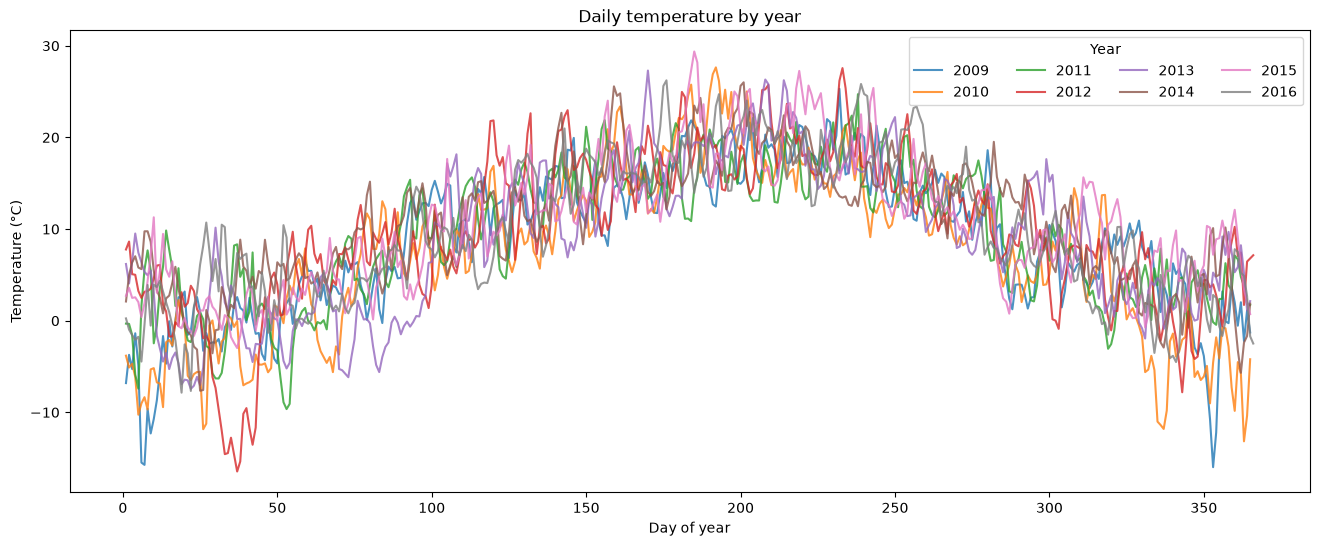

In [85]:
daily = daily_T.to_frame('T').reset_index()
daily['year'] = daily['Date Time'].dt.year
daily['dayofyear'] = daily['Date Time'].dt.dayofyear

plt.figure(figsize = (16,6))
for year, g in daily.groupby('year'):
    if len(g) >= 300:
        sns.lineplot(x='dayofyear', y='T', data=g, label=str(year), alpha=0.8)
plt.title('Daily temperature by year')
plt.xlabel('Day of year')
plt.ylabel('Temperature (°C)')
plt.legend(title='Year', ncol=4)
plt.savefig('images/Daily temperature by year.png', dpi=300, bbox_inches='tight')
plt.show()

## 5.6 Daily value by variable

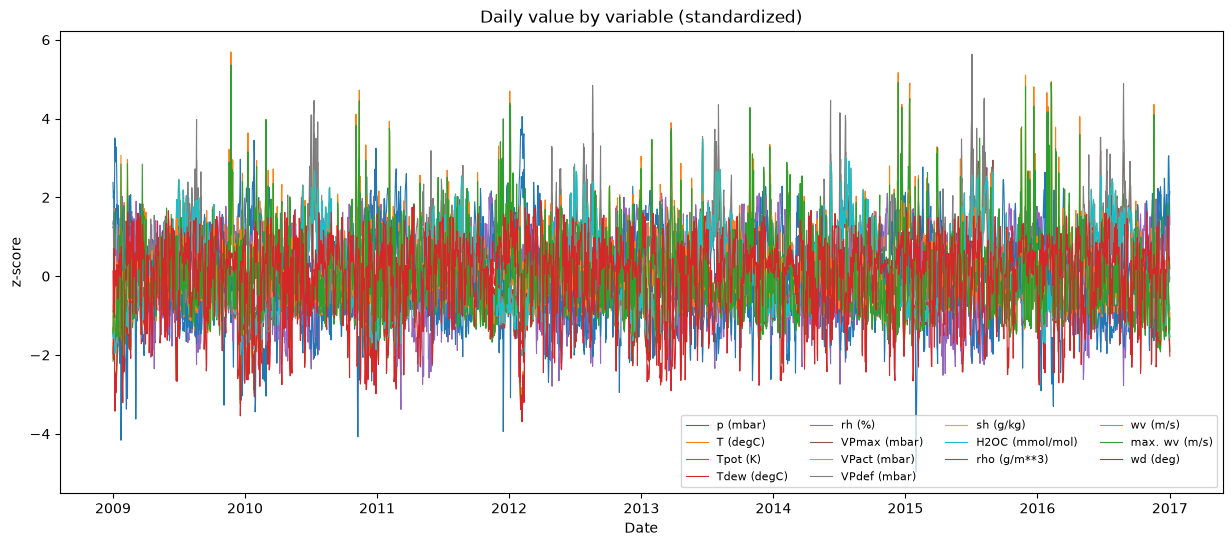

In [86]:
daily_all = df.resample('1D').mean()

std_all = (daily_all - daily_all.mean()) / daily_all.std()

plt.figure(figsize=(15, 6))
for c in std_all.columns:
    sns.lineplot(x=std_all.index, y=std_all[c], label=c, linewidth=0.8)
plt.title('Daily value by variable (standardized)')
plt.xlabel('Date')
plt.ylabel('z-score')
plt.legend(ncol=4, fontsize=8)
plt.savefig('images/Daily value by variable', dpi=300, bbox_inches='tight')
plt.show()

## 5.7 Pola musiman

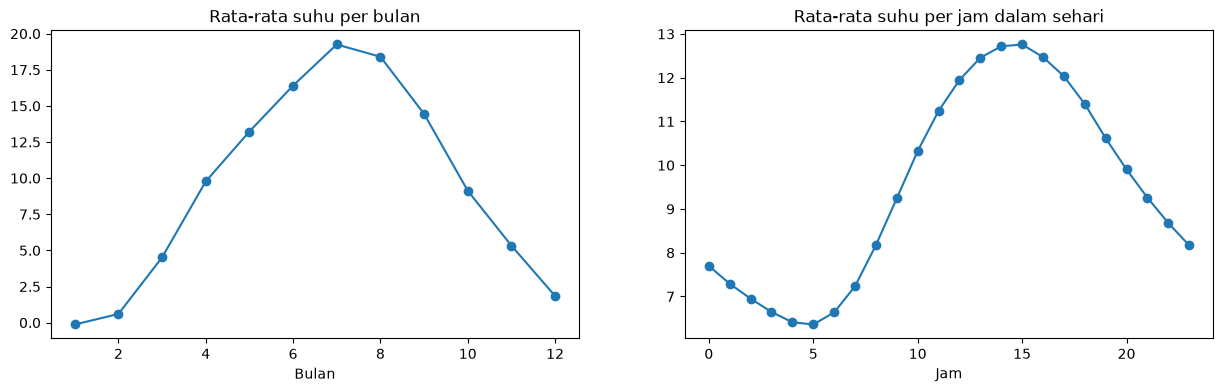

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df.groupby(df.index.month)['T (degC)'].mean().plot(ax=ax[0], marker='o')
ax[0].set_title('Rata-rata suhu per bulan'); ax[0].set_xlabel('Bulan')
df.groupby(df.index.hour)['T (degC)'].mean().plot(ax=ax[1], marker='o')
ax[1].set_title('Rata-rata suhu per jam dalam sehari'); ax[1].set_xlabel('Jam')
plt.savefig('images/Pola Musiman', dpi=300, bbox_inches='tight')
plt.show()

# 6. Preprocessing

## 6.1 Arah angin menjadi vektor

In [88]:
rad = np.deg2rad(df['wd (deg)'])
df['Wx']= df['wv (m/s)']* np.cos(rad)
df ['Wy']= df['wv (m/s)']*np.sin(rad)
df = df.drop(columns=['wv (m/s)', 'max. wv (m/s)', 'wd (deg)'])
df.columns.tolist()


['p (mbar)',
 'T (degC)',
 'Tpot (K)',
 'Tdew (degC)',
 'rh (%)',
 'VPmax (mbar)',
 'VPact (mbar)',
 'VPdef (mbar)',
 'sh (g/kg)',
 'H2OC (mmol/mol)',
 'rho (g/m**3)',
 'Wx',
 'Wy']

## 6.2 Agregasi perjam

In [89]:
df = df.resample('1h').mean().interpolate(method='time')
print(df.shape, '| NaN:', df.isna().sum().sum())
df.head()


(70129, 13) | NaN: 0


,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),Wx,Wy
Date Time,,,,,,,,,,,,,
2009-01-01 00:00:00,996.528000,-8.304000,265.118000,-9.120000,93.780000,3.260000,3.058000,0.202000,1.910000,3.068000,1309.196000,-0.441285,0.144080
2009-01-01 01:00:00,996.525000,-8.065000,265.361667,-8.861667,93.933333,3.323333,3.121667,0.201667,1.951667,3.133333,1307.981667,-0.297470,0.007457
2009-01-01 02:00:00,996.745000,-8.763333,264.645000,-9.610000,93.533333,3.145000,2.940000,0.201667,1.836667,2.950000,1311.816667,-0.216609,-0.025517
2009-01-01 03:00:00,996.986667,-8.896667,264.491667,-9.786667,93.200000,3.111667,2.898333,0.210000,1.811667,2.906667,1312.813333,-0.140886,0.064960
2009-01-01 04:00:00,997.158333,-9.348333,264.026667,-10.345000,92.383333,3.001667,2.775000,0.231667,1.733333,2.780000,1315.355000,-0.101078,0.178436


## 7. Split dan penyamaan skala data

## 7.1 Split berdasarkan waktu

In [90]:
train, temp = train_test_split(df, test_size= 0.3, shuffle=False)
val, test = train_test_split(temp, test_size=0.50,shuffle=False)

print('Train:', train.index.min(), '->', train.index.max())
print('Val  :', val.index.min(), '->', val.index.max())
print('Test :', test.index.min(), '->', test.index.max())
print(len(train), len(val), len(test))


Train: 2009-01-01 00:00:00 -> 2014-08-08 09:00:00
Val  : 2014-08-08 10:00:00 -> 2015-10-20 16:00:00
Test : 2015-10-20 17:00:00 -> 2017-01-01 00:00:00
49090 10519 10520


## 7.2 Standarisasi

In [91]:
mu, sd = train.mean(), train.std()
train_s, val_s, test_s = [((d - mu) / sd).values for d in (train, val, test)]

# 8. preprocessing Lanjutan

## 8.1 Windowing

In [92]:
WINDOW, HORIZON = 24, 1
TARGET = 'T (degC)'
T_IDX = df.columns.get_loc(TARGET)

def buat_window(arr, target_idx, window, horizon=1):
    X = sliding_window_view(arr, window, axis=0).transpose(0, 2, 1)
    X = X[: len(arr) - window - horizon + 1]
    y = arr[window + horizon - 1:, target_idx]
    return X, y

X_tr, y_tr = buat_window(train_s, T_IDX, WINDOW, HORIZON)
X_va, y_va = buat_window(val_s,   T_IDX, WINDOW, HORIZON)
X_te, y_te = buat_window(test_s,  T_IDX, WINDOW, HORIZON)
F = X_tr.shape[2]
print('Train', X_tr.shape, '\n| Val', X_va.shape, '\n| Test', X_te.shape)

Train (49066, 24, 13) 
| Val (10495, 24, 13) 
| Test (10496, 24, 13)


# 9. RNN for Time Series Forecasting

In [93]:
epochs = 30
batch = 256
lr = 0.001
early_stop = EarlyStopping(patience=5, restore_best_weights=True)


keras.utils.set_random_seed(1)
model_rnn = Sequential()
model_rnn.add(Input(shape=(X_tr.shape[1], X_tr.shape[2])))
model_rnn.add(SimpleRNN(units=64, activation='tanh'))
model_rnn.add(Dense(1))
model_rnn.compile(optimizer=Adam(learning_rate=lr), loss='mse')
model_rnn.summary()        
                           

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_10 (SimpleRNN)       │ (None, 64)             │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [94]:
rnn_history = model_rnn.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                            epochs=epochs, batch_size=batch, verbose=2,
                            callbacks=[early_stop])

Epoch 1/30
192/192 - 9s - 45ms/step - loss: 0.0774 - val_loss: 0.0126
Epoch 2/30
192/192 - 4s - 19ms/step - loss: 0.0106 - val_loss: 0.0088
Epoch 3/30
192/192 - 2s - 10ms/step - loss: 0.0080 - val_loss: 0.0075
Epoch 4/30
192/192 - 2s - 11ms/step - loss: 0.0069 - val_loss: 0.0068
Epoch 5/30
192/192 - 2s - 11ms/step - loss: 0.0063 - val_loss: 0.0064
Epoch 6/30
192/192 - 2s - 10ms/step - loss: 0.0060 - val_loss: 0.0061
Epoch 7/30
192/192 - 2s - 11ms/step - loss: 0.0058 - val_loss: 0.0059
Epoch 8/30
192/192 - 2s - 8ms/step - loss: 0.0056 - val_loss: 0.0058
Epoch 9/30
192/192 - 2s - 8ms/step - loss: 0.0055 - val_loss: 0.0057
Epoch 10/30
192/192 - 2s - 10ms/step - loss: 0.0054 - val_loss: 0.0056
Epoch 11/30
192/192 - 2s - 9ms/step - loss: 0.0053 - val_loss: 0.0055
Epoch 12/30
192/192 - 2s - 10ms/step - loss: 0.0053 - val_loss: 0.0054
Epoch 13/30
192/192 - 2s - 11ms/step - loss: 0.0052 - val_loss: 0.0054
Epoch 14/30
192/192 - 2s - 9ms/step - loss: 0.0051 - val_loss: 0.0053
Epoch 15/30
192/192

# 10. LSTM for Time Series Forecasting

In [95]:
keras.utils.set_random_seed(1)
model_lstm = Sequential()
model_lstm.add(Input(shape=(X_tr.shape[1], X_tr.shape[2])))
model_lstm.add(LSTM(units=64))
model_lstm.add(Dense(1))
model_lstm.compile(optimizer=Adam(learning_rate=lr), loss='mse')
model_lstm.summary()


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 64)             │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
lstm_history = model_lstm.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                              epochs=epochs, batch_size=batch, verbose=2,
                              callbacks=[early_stop])

Epoch 1/30
192/192 - 9s - 45ms/step - loss: 0.0535 - val_loss: 0.0148
Epoch 2/30
192/192 - 6s - 33ms/step - loss: 0.0108 - val_loss: 0.0089
Epoch 3/30
192/192 - 6s - 33ms/step - loss: 0.0071 - val_loss: 0.0061
Epoch 4/30
192/192 - 6s - 30ms/step - loss: 0.0055 - val_loss: 0.0052
Epoch 5/30
192/192 - 10s - 51ms/step - loss: 0.0051 - val_loss: 0.0049
Epoch 6/30
192/192 - 5s - 28ms/step - loss: 0.0049 - val_loss: 0.0048
Epoch 7/30
192/192 - 6s - 32ms/step - loss: 0.0047 - val_loss: 0.0047
Epoch 8/30
192/192 - 6s - 31ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 9/30
192/192 - 6s - 32ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 10/30
192/192 - 6s - 32ms/step - loss: 0.0045 - val_loss: 0.0045
Epoch 11/30
192/192 - 6s - 31ms/step - loss: 0.0045 - val_loss: 0.0045
Epoch 12/30
192/192 - 6s - 31ms/step - loss: 0.0044 - val_loss: 0.0045
Epoch 13/30
192/192 - 10s - 51ms/step - loss: 0.0044 - val_loss: 0.0045
Epoch 14/30
192/192 - 10s - 55ms/step - loss: 0.0044 - val_loss: 0.0044
Epoch 15/30


# 11. Skala suhu, fungsi evaluasi, dan baseline naive

In [97]:
mu_T = mu['T (degC)'] if np.ndim(mu) > 0 else mu
sd_T = sd['T (degC)'] if np.ndim(sd) > 0 else sd

def rmse_c(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2)) * sd_T

def mae_c(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred)) * sd_T

def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

naive_te = X_te[:, -1, T_IDX]
print('Naive | RMSE %.3f °C | MAE %.3f °C | R² %.4f'
      % (rmse_c(y_te, naive_te), mae_c(y_te, naive_te), r2(y_te, naive_te)))

Naive | RMSE 0.901 °C | MAE 0.642 °C | R² 0.9866


# 12. Kurva train loss dan validation loss

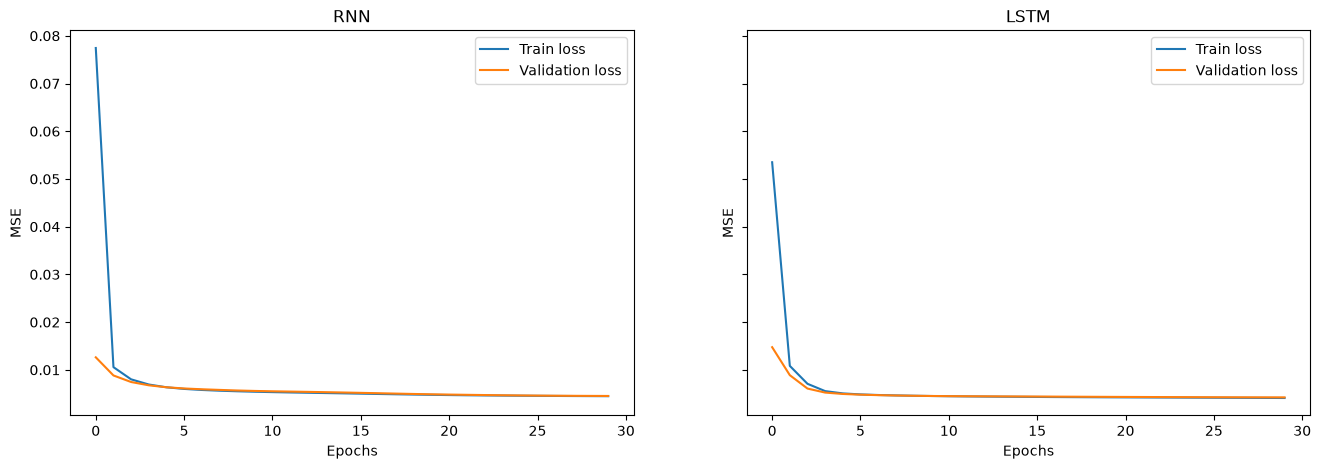

In [98]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(16, 5))
ax1, ax2 = axes

ax1.plot(rnn_history.history['loss'], label='Train loss')
ax1.plot(rnn_history.history['val_loss'], label='Validation loss')
ax1.legend(loc='best'); ax1.set_title('RNN'); ax1.set_xlabel('Epochs'); ax1.set_ylabel('MSE')

ax2.plot(lstm_history.history['loss'], label='Train loss')
ax2.plot(lstm_history.history['val_loss'], label='Validation loss')
ax2.legend(loc='best'); ax2.set_title('LSTM'); ax2.set_xlabel('Epochs'); ax2.set_ylabel('MSE')
plt.savefig('images/Kurva train loss dan validation loss', dpi=300, bbox_inches='tight')
plt.show()

# 13. Prediksi dan metrik pada train, validasi, dan uji

In [99]:
rnn_train_pred = model_rnn.predict(X_tr, verbose=0).ravel()
rnn_valid_pred = model_rnn.predict(X_va, verbose=0).ravel()
rnn_test_pred = model_rnn.predict(X_te, verbose=0).ravel()

lstm_train_pred = model_lstm.predict(X_tr, verbose=0).ravel()
lstm_valid_pred = model_lstm.predict(X_va, verbose=0).ravel()
lstm_test_pred = model_lstm.predict(X_te, verbose=0).ravel()

for nama, (ptr, pva, pte) in {'RNN': (rnn_train_pred, rnn_valid_pred, rnn_test_pred),
                              'LSTM': (lstm_train_pred, lstm_valid_pred, lstm_test_pred)}.items():
    print('%-5s RMSE (°C) | Train %.3f | Val %.3f | Test %.3f'
          % (nama, rmse_c(y_tr, ptr), rmse_c(y_va, pva), rmse_c(y_te, pte)))
    print('%-5s R²        | Train %.4f | Val %.4f | Test %.4f'
          % (nama, r2(y_tr, ptr), r2(y_va, pva), r2(y_te, pte)))

RNN   RMSE (°C) | Train 0.570 | Val 0.582 | Test 0.546
RNN   R²        | Train 0.9957 | Val 0.9943 | Test 0.9951
LSTM  RMSE (°C) | Train 0.547 | Val 0.563 | Test 0.529
LSTM  R²        | Train 0.9960 | Val 0.9947 | Test 0.9954


In [100]:
tabel = pd.DataFrame({
    'Model': ['Naive', 'RNN', 'LSTM'],
    'RMSE test (°C)': [rmse_c(y_te, naive_te), rmse_c(y_te, rnn_test_pred), rmse_c(y_te, lstm_test_pred)],
    'MAE test (°C)': [mae_c(y_te, naive_te), mae_c(y_te, rnn_test_pred), mae_c(y_te, lstm_test_pred)],
    'R² test': [r2(y_te, naive_te), r2(y_te, rnn_test_pred), r2(y_te, lstm_test_pred)],
    'Parameter': [0, model_rnn.count_params(), model_lstm.count_params()]}).round(4)
tabel

,Model,RMSE test (°C),MAE test (°C),R² test,Parameter
0,Naive,0.9009,0.6425,0.9866,0
1,RNN,0.5460,0.3817,0.9951,5057
2,LSTM,0.5287,0.3672,0.9954,20033


# 14. Prediksi vs aktual

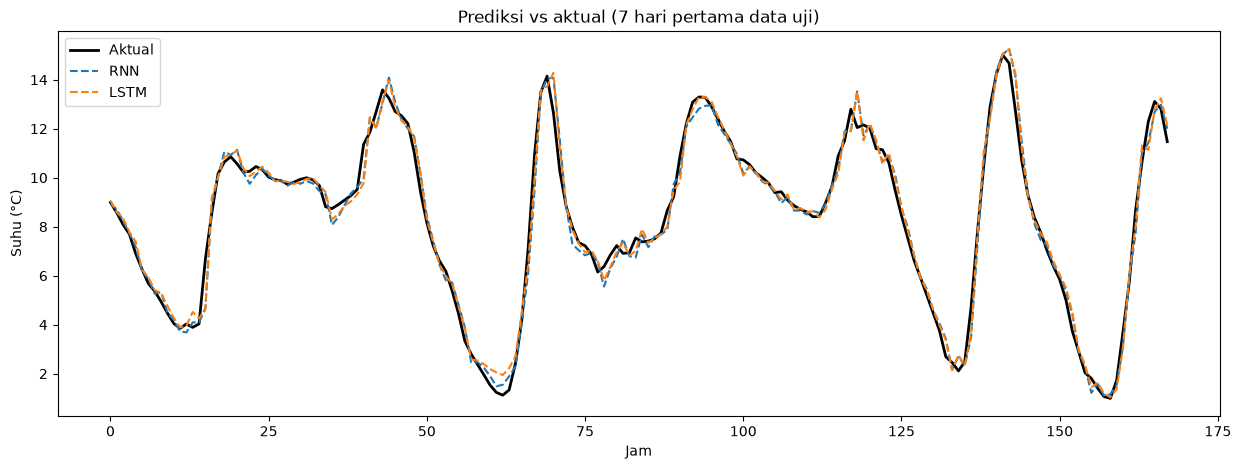

In [101]:
aktual_c = y_te * sd_T + mu_T
rnn_c = rnn_test_pred * sd_T + mu_T
lstm_c = lstm_test_pred * sd_T + mu_T

plt.figure(figsize=(15, 5))
plt.plot(aktual_c[:168], label='Aktual', color='black', linewidth=2)
plt.plot(rnn_c[:168], label='RNN', linestyle='--')
plt.plot(lstm_c[:168], label='LSTM', linestyle='--')
plt.title('Prediksi vs aktual (7 hari pertama data uji)')
plt.xlabel('Jam'); plt.ylabel('Suhu (°C)'); plt.legend()
plt.savefig('images/Prediksi vs aktual', dpi=300, bbox_inches='tight')
plt.show()

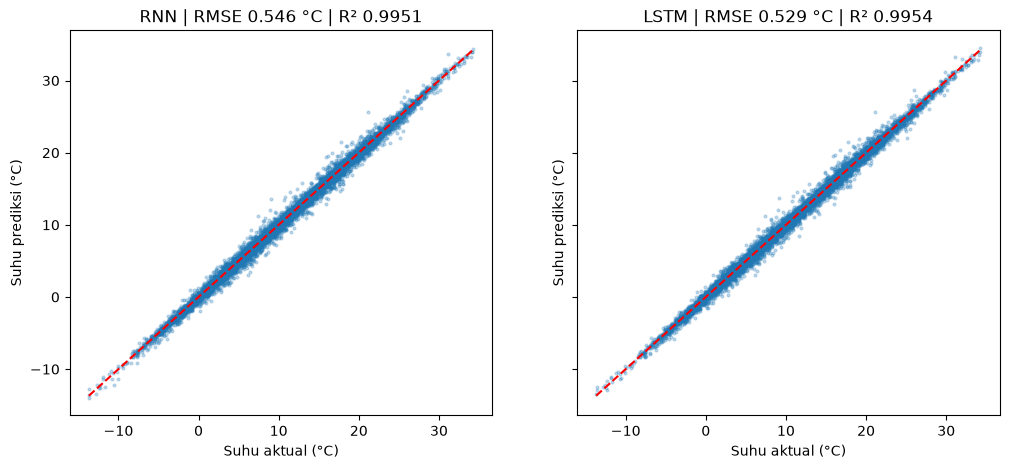

In [102]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lo, hi = aktual_c.min(), aktual_c.max()
for a, nama, p_std, p_c in zip(ax, ['RNN', 'LSTM'],
                               [rnn_test_pred, lstm_test_pred], [rnn_c, lstm_c]):
    a.scatter(aktual_c, p_c, s=4, alpha=0.25)
    a.plot([lo, hi], [lo, hi], color='red', linestyle='--')
    a.set_title('%s | RMSE %.3f °C | R² %.4f' % (nama, rmse_c(y_te, p_std), r2(y_te, p_std)))
    a.set_xlabel('Suhu aktual (°C)'); a.set_ylabel('Suhu prediksi (°C)')
plt.savefig('images/Sccaterplot Prediksi vs aktual', dpi=300, bbox_inches='tight')
plt.show()

In [103]:
F = X_tr.shape[2]
WINDOWS, SEEDS = [12, 24, 48], [1, 2, 3]

def bangun_model(jenis, window):
    model = Sequential()
    model.add(Input(shape=(window, F)))
    if jenis == 'RNN':
        model.add(SimpleRNN(units=64, activation='tanh'))
    else:
        model.add(LSTM(units=64))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

def jalankan(jenis, window, seed):
    Xtr, ytr = buat_window(train_s, T_IDX, window)
    Xva, yva = buat_window(val_s, T_IDX, window)
    Xte, yte = buat_window(test_s, T_IDX, window)
    keras.utils.set_random_seed(seed)
    model = bangun_model(jenis, window)
    model.fit(Xtr, ytr, validation_data=(Xva, yva),
              epochs=epochs, batch_size=batch, verbose=0,
              callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])
    pred = model.predict(Xte, verbose=0).ravel()
    naive = Xte[:, -1, T_IDX]
    return rmse_c(yte, pred), rmse_c(yte, naive), r2(yte, pred)

rekap = []
for window in WINDOWS:
    for jenis in ['RNN', 'LSTM']:
        for seed in SEEDS:
            rmse, rmse_naive_w, r2_val = jalankan(jenis, window, seed)
            rekap.append({'Window': window, 'Model': jenis, 'Seed': seed,
                          'RMSE': rmse, 'RMSE_naive': rmse_naive_w, 'R2': r2_val})

hasil = pd.DataFrame(rekap)
ringkas = (hasil.groupby(['Window', 'Model'])
           .agg(RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
                R2_mean=('R2', 'mean'), Naive=('RMSE_naive', 'mean'))
           .round(4))
ringkas

RMSE_mean  RMSE_std  R2_mean   Naive
Window Model                                      
12     LSTM      0.5609    0.0086   0.9948  0.9004
       RNN       0.5783    0.0074   0.9945  0.9004
24     LSTM      0.5359    0.0066   0.9953  0.9009
       RNN       0.5550    0.0087   0.9949  0.9009
48     LSTM      0.5340    0.0076   0.9953  0.9010
       RNN       0.5616    0.0096   0.9948  0.9010

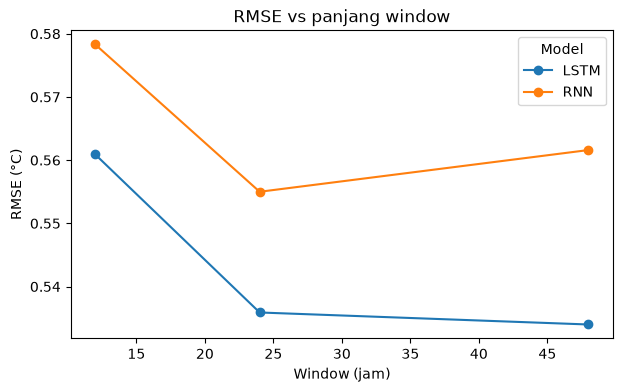

In [104]:
ringkas['RMSE_mean'].unstack().plot(marker='o', figsize=(7, 4), title='RMSE vs panjang window')
plt.ylabel('RMSE (°C)'); plt.xlabel('Window (jam)')
plt.savefig('images/RMSE vs panjang window', dpi=300, bbox_inches='tight')
plt.show()